In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Multi-Fidelity Hyperparameter Optimization

Training neural networks can be expensive even on moderate size datasets.
Depending on the configuration space (that section),
hyperparameter optimization requires tens to hundreds of function evaluations
to find a well-performing hyperparameter configuration. As we have seen in
that section, we can significantly speed up the overall wall-clock
time of HPO by exploiting parallel resources, but this does not reduce the total
amount of compute required.

In this section, we will show how the evaluation of hyperparameter configurations
can be sped up. Methods such as random search allocate the same amount of
resources (e.g., number of epochs, training data points) to each hyperparameter
evaluation. the figure depicts learning curves of a set of neural
networks trained with different hyperparameter configurations. After a few epochs we are
already able to visually distinguish between well-performing and suboptimal
configurations. However, the learning curves are noisy, and we might still require
the full amount of 100 epochs to identify the best performing one.

![Learning curves of random hyperparameter configurations](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/samples_lc.svg)

Multi-fidelity hyperparameter optimization allocates more resources
to promising configurations and stops evaluations of poorly performing ones early.
This speeds up the optimization process, since we can try a larger number of
configurations for the same total amount of resources.

More formally, we expand our definition in that section,
such that our objective function $f(\mathbf{x}, r)$ gets an additional input
$r \in [r_{\mathrm{min}}, r_{\mathrm{max}}]$, specifying the amount of resources that we are
willing to spend for the evaluation of configuration $\mathbf{x}$. We assume that
the error $f(\mathbf{x}, r)$ decreases with $r$, whereas the computational
cost $c(\mathbf{x}, r)$ increases. Typically, $r$ represents the number of
epochs for training the neural network, but it could also be the training
subset size or the number of cross-validation folds.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

In [ ]:
from collections import defaultdict
from scipy import stats

In [ ]:
d2l.set_figsize()

## Successive Halving

One of the simplest ways to adapt random search to the multi-fidelity setting is
*successive halving* [@jamieson-aistats16; @karnin-icml13]. The basic
idea is to start with $N$ configurations, for example randomly sampled from the
configuration space, and to train each of them for $r_{\mathrm{min}}$ epochs only. We
then discard a fraction of the worst performing trials and train the remaining
ones for longer. Iterating this process, fewer trials run for longer, until at
least one trial reaches $r_{\mathrm{max}}$ epochs.

More formally, consider a minimum budget $r_{\mathrm{min}}$ (for example 1 epoch), a maximum
budget $r_{\mathrm{max}}$, for example `max_epochs` in our previous example, and a halving
constant $\eta\in\{2, 3, \dots\}$. For simplicity, assume that
$r_{\mathrm{max}} = r_{\mathrm{min}} \eta^K$, with $K \in \mathbb{N}$. The number of initial
configurations is then $N = \eta^K$. Let us define the set of rungs
$\mathcal{R} = \{ r_{\mathrm{min}}, r_{\mathrm{min}}\eta, r_{\mathrm{min}}\eta^2, \dots, r_{\mathrm{max}} \}$.

One round of successive halving proceeds as follows. We start with running $N$
trials until the first rung $r_{\mathrm{min}}$. Sorting the validation errors, we keep
the top $1 / \eta$ fraction (which amounts to $\eta^{K-1}$ configurations) and
discard all the rest. The surviving trials are trained for the next rung
($r_{\mathrm{min}}\eta$ epochs), and the process is repeated. At each rung, a
$1 / \eta$ fraction of trials survives and their training continues with a
$\eta$ times larger budget. With this particular choice of $N$, only a single
trial will be trained to the full budget $r_{\mathrm{max}}$. Once such a round of
successive halving is done, we start the next one with a new set of initial
configurations, iterating until the total budget is spent.

![Learning curves of random hyperparameter configurations.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/sh.svg)

We subclass the `HPOScheduler` base class from that section in order to
implement successive halving, allowing for a generic `HPOSearcher` object to
sample configurations (which, in our example below, will be a `RandomSearcher`).
Additionally, the user has to pass the minimum resource $r_{\mathrm{min}}$, the maximum
resource $r_{\mathrm{max}}$ and $\eta$ as input. Inside our scheduler, we maintain a
queue of configurations that still need to be evaluated for the current rung
$r_i$. We update the queue every time we jump to the next rung.

In [2]:
class SuccessiveHalvingScheduler(d2l.HPOScheduler):
    def __init__(self, searcher, eta, r_min, r_max, prefact=1):
        self.save_hyperparameters()
        # Compute K, which is later used to determine the number of configurations
        self.K = int(np.log(r_max / r_min) / np.log(eta))
        # Define the rungs
        self.rung_levels = [r_min * eta ** k for k in range(self.K + 1)]
        if r_max not in self.rung_levels:
            # The final rung should be r_max
            self.rung_levels.append(r_max)
            self.K += 1
        # Bookkeeping
        self.observed_error_at_rungs = defaultdict(list)
        self.all_observed_error_at_rungs = defaultdict(list)
        # Our processing queue
        self.queue = []

In the beginning our queue is empty, and we fill it with
$n = \textrm{prefact} \cdot \eta^{K}$ configurations, which are first evaluated on
the smallest rung $r_{\mathrm{min}}$. Here, $\textrm{prefact}$ allows us to reuse our
code in a different context. For the purpose of this section, we fix
$\textrm{prefact} = 1$. Every time resources become available and the `HPOTuner`
object queries the `suggest` function, we return an element from the queue. Once
we finish one round of successive halving, which means that we evaluated all
surviving configurations on the highest resource level $r_{\mathrm{max}}$ and our queue
is empty, we start the entire process again with a new, randomly sampled set
of configurations.

In [3]:
@d2l.add_to_class(SuccessiveHalvingScheduler)
def suggest(self):
    if len(self.queue) == 0:
        # Start a new round of successive halving
        # Number of configurations for the first rung:
        n0 = int(self.prefact * self.eta ** self.K)
        for _ in range(n0):
            config = self.searcher.sample_configuration()
            config["max_epochs"] = self.r_min  # Set r = r_min
            self.queue.append(config)
    # Return an element from the queue
    return self.queue.pop()

When we collected a new data point, we first update the searcher module.
Afterwards we check if we have already collected all data points on the current rung.
If so, we sort all configurations and push the top $\frac{1}{\eta}$
configurations into the queue.

In [4]:
@d2l.add_to_class(SuccessiveHalvingScheduler)
def update(self, config: dict, error: float, info=None):
    ri = int(config["max_epochs"])  # Rung r_i
    # Update our searcher, e.g if we use Bayesian optimization later
    self.searcher.update(config, error, additional_info=info)
    self.all_observed_error_at_rungs[ri].append((config, error))
    if ri < self.r_max:
        # Bookkeeping
        self.observed_error_at_rungs[ri].append((config, error))
        # Determine how many configurations should be evaluated on this rung
        ki = self.K - self.rung_levels.index(ri)
        ni = int(self.prefact * self.eta ** ki)
        # If we observed all configuration on this rung r_i, we estimate the
        # top 1 / eta configuration, add them to queue and promote them for
        # the next rung r_{i+1}
        if len(self.observed_error_at_rungs[ri]) >= ni:
            kiplus1 = ki - 1
            niplus1 = int(self.prefact * self.eta ** kiplus1)
            best_performing_configurations = self.get_top_n_configurations(
                rung_level=ri, n=niplus1
            )
            riplus1 = self.rung_levels[self.K - kiplus1]  # r_{i+1}
            # Queue may not be empty: insert new entries at the beginning
            self.queue = [
                dict(config, max_epochs=riplus1)
                for config in best_performing_configurations
            ] + self.queue
            self.observed_error_at_rungs[ri] = []  # Reset

Configurations are sorted based on their observed performance on the current
rung.

In [5]:

@d2l.add_to_class(SuccessiveHalvingScheduler)
def get_top_n_configurations(self, rung_level, n):
    rung = self.observed_error_at_rungs[rung_level]
    if not rung:
        return []
    sorted_rung = sorted(rung, key=lambda x: x[1])
    return [x[0] for x in sorted_rung[:n]]

Let us see how successive halving is doing on our neural network example. We
will use $r_{\mathrm{min}} = 2$, $\eta = 2$, $r_{\mathrm{max}} = 10$, so that rung levels are
$2, 4, 8, 10$.

In [6]:
min_number_of_epochs = 2
max_number_of_epochs = 10
eta = 2
num_gpus=1

config_space = {
    "learning_rate": stats.loguniform(1e-2, 1),
    "batch_size": stats.randint(32, 256),
}
initial_config = {
    "learning_rate": 0.1,
    "batch_size": 128,
}

We just replace the scheduler with our new `SuccessiveHalvingScheduler`.

Trial 0: learning_rate = 0.0101, batch_size = 70, max_epochs = 2


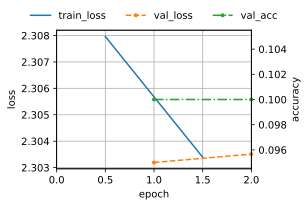

    error = 0.9000, runtime = 17.4 s
Trial 1: learning_rate = 0.7639, batch_size = 135, max_epochs = 2


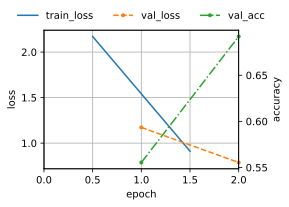

    error = 0.3080, runtime = 9.5 s
Trial 2: learning_rate = 0.09296, batch_size = 102, max_epochs = 2


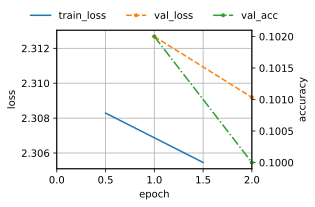

    error = 0.9000, runtime = 10.6 s
Trial 3: learning_rate = 0.9844, batch_size = 235, max_epochs = 2


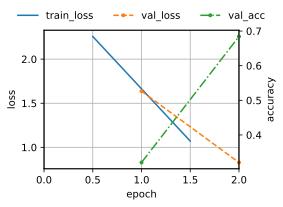

    error = 0.3157, runtime = 11.5 s
Trial 4: learning_rate = 0.02638, batch_size = 213, max_epochs = 2


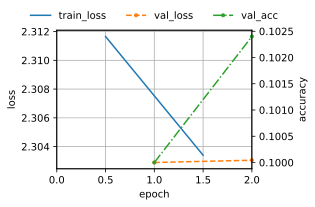

    error = 0.8976, runtime = 11.7 s
Trial 5: learning_rate = 0.1147, batch_size = 43, max_epochs = 2


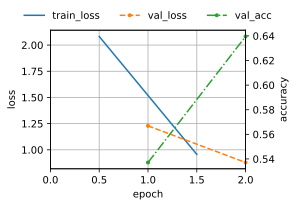

    error = 0.3605, runtime = 13.7 s
Trial 6: learning_rate = 0.03297, batch_size = 240, max_epochs = 2


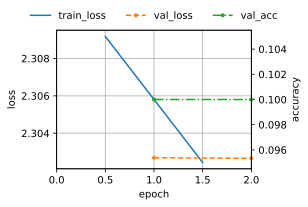

    error = 0.9000, runtime = 7.6 s
Trial 7: learning_rate = 0.1, batch_size = 128, max_epochs = 2


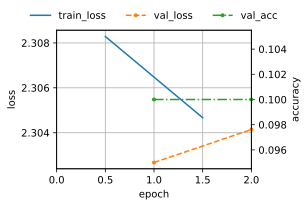

    error = 0.9000, runtime = 12.5 s
Trial 8: learning_rate = 0.02638, batch_size = 213, max_epochs = 4


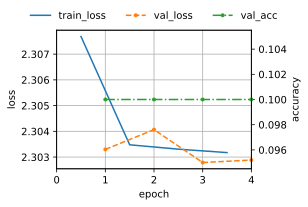

    error = 0.9000, runtime = 6.0 s
Trial 9: learning_rate = 0.1147, batch_size = 43, max_epochs = 4


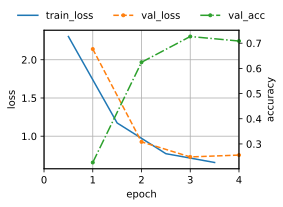

    error = 0.2913, runtime = 15.4 s
Trial 10: learning_rate = 0.9844, batch_size = 235, max_epochs = 4


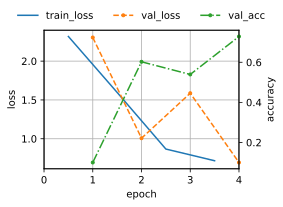

    error = 0.2714, runtime = 5.7 s
Trial 11: learning_rate = 0.7639, batch_size = 135, max_epochs = 4


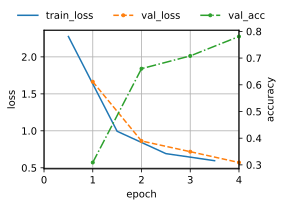

    error = 0.2192, runtime = 7.4 s
Trial 12: learning_rate = 0.9844, batch_size = 235, max_epochs = 8


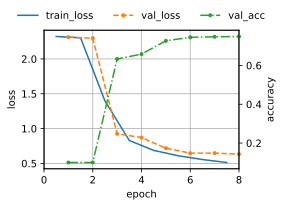

    error = 0.2511, runtime = 8.5 s
Trial 13: learning_rate = 0.7639, batch_size = 135, max_epochs = 8


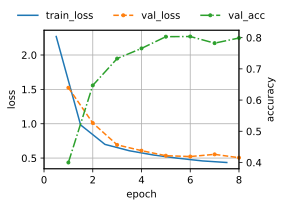

    error = 0.2011, runtime = 11.9 s
Trial 14: learning_rate = 0.7639, batch_size = 135, max_epochs = 10


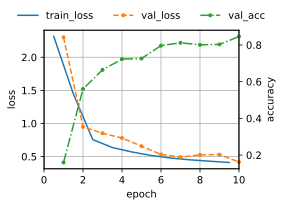

    error = 0.1538, runtime = 14.2 s
Trial 15: learning_rate = 0.07283, batch_size = 48, max_epochs = 2


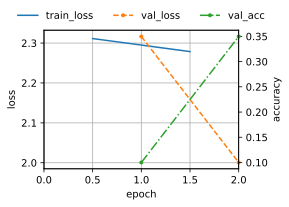

    error = 0.6503, runtime = 11.6 s
Trial 16: learning_rate = 0.0299, batch_size = 189, max_epochs = 2


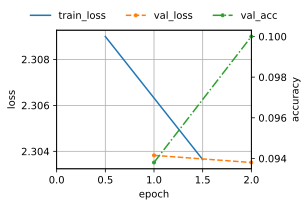

    error = 0.9000, runtime = 12.4 s
Trial 17: learning_rate = 0.1372, batch_size = 36, max_epochs = 2


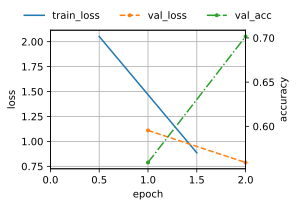

    error = 0.2984, runtime = 13.8 s
Trial 18: learning_rate = 0.0489, batch_size = 132, max_epochs = 2


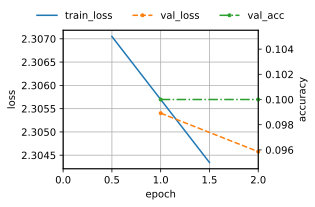

    error = 0.9000, runtime = 11.4 s
Trial 19: learning_rate = 0.07568, batch_size = 132, max_epochs = 2


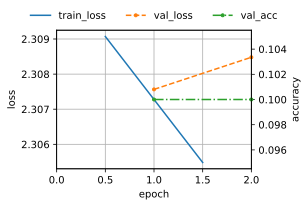

    error = 0.9000, runtime = 5.2 s
Trial 20: learning_rate = 0.0578, batch_size = 237, max_epochs = 2


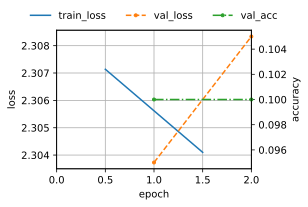

    error = 0.9000, runtime = 10.3 s
Trial 21: learning_rate = 0.04443, batch_size = 93, max_epochs = 2


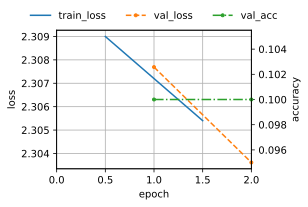

    error = 0.9000, runtime = 10.1 s
Trial 22: learning_rate = 0.4877, batch_size = 199, max_epochs = 2


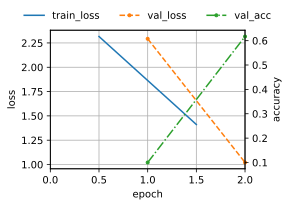

    error = 0.3830, runtime = 11.8 s
Trial 23: learning_rate = 0.0299, batch_size = 189, max_epochs = 4


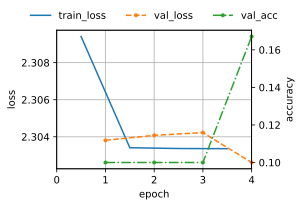

    error = 0.8329, runtime = 6.4 s
Trial 24: learning_rate = 0.07283, batch_size = 48, max_epochs = 4


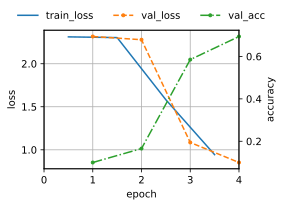

    error = 0.3061, runtime = 13.8 s
Trial 25: learning_rate = 0.4877, batch_size = 199, max_epochs = 4


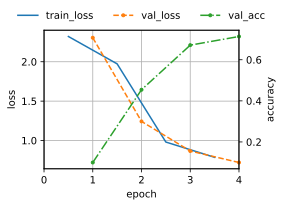

    error = 0.2868, runtime = 6.3 s
Trial 26: learning_rate = 0.1372, batch_size = 36, max_epochs = 4


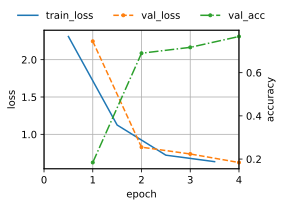

    error = 0.2327, runtime = 18.4 s
Trial 27: learning_rate = 0.4877, batch_size = 199, max_epochs = 8


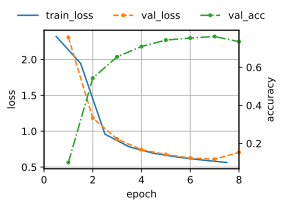

    error = 0.2654, runtime = 9.8 s
Trial 28: learning_rate = 0.1372, batch_size = 36, max_epochs = 8


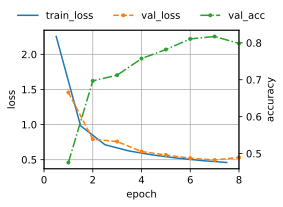

    error = 0.2016, runtime = 34.5 s
Trial 29: learning_rate = 0.1372, batch_size = 36, max_epochs = 10


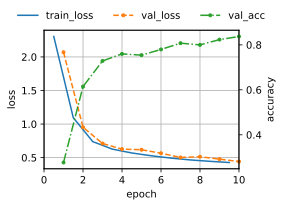

    error = 0.1629, runtime = 41.3 s


In [7]:
searcher = d2l.RandomSearcher(config_space, initial_config=initial_config)
scheduler = SuccessiveHalvingScheduler(
    searcher=searcher,
    eta=eta,
    r_min=min_number_of_epochs,
    r_max=max_number_of_epochs,
)
tuner = d2l.HPOTuner(
    scheduler=scheduler,
    objective=d2l.hpo_objective_lenet,
)
tuner.run(number_of_trials=30)

We can visualize the learning curves of all configurations that we evaluated.
Most of the configurations are stopped early and only the better performing
configurations survive until $r_{\mathrm{max}}$. Compare this to vanilla random search,
which would allocate $r_{\mathrm{max}}$ to every configuration.

Text(0.5, 0, 'epochs')

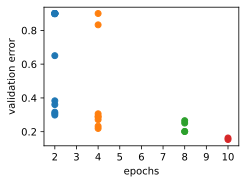

In [8]:
for rung_index, rung in scheduler.all_observed_error_at_rungs.items():
    errors = [xi[1] for xi in rung]
    d2l.plt.scatter([rung_index] * len(errors), errors)
d2l.plt.xlim(min_number_of_epochs - 0.5, max_number_of_epochs + 0.5)
d2l.plt.xticks(
    np.arange(min_number_of_epochs, max_number_of_epochs + 1),
    np.arange(min_number_of_epochs, max_number_of_epochs + 1)
)
d2l.plt.ylabel("validation error")
d2l.plt.xlabel("epochs")

Finally, note some slight complexity in our implementation of
`SuccessiveHalvingScheduler`. Say that a worker is free to run a job, and
`suggest` is called when the current rung has almost been completely filled, but
another worker is still busy with an evaluation. Since we lack the metric value
from this worker, we cannot determine the top $1 / \eta$ fraction to open up
the next rung. On the other hand, we want to assign a job to our free worker,
so it does not remain idle. Our solution is to start a new round of successive
halving and assign our worker to the first trial there. However, once a rung is
completed in `update`, we make sure to insert new configurations at the
beginning of the queue, so they take precedence over configurations from the
next round.

## Summary

In this section, we introduced the concept of multi-fidelity hyperparameter
optimization, where we assume to have access to cheap-to-evaluate approximations
of the objective function, such as validation error after a certain number of
epochs of training as proxy to validation error after the full number of epochs.
Multi-fidelity hyperparameter optimization allows to reduce the overall
computation of the HPO instead of just reducing the wall-clock time.

We implemented and evaluated successive halving, a simple yet efficient
multi-fidelity HPO algorithm.

## Exercises

1. Consider one round of successive halving with $N = \eta^K$ configurations and $r_{\mathrm{max}} = r_{\mathrm{min}}\eta^K$, in which every trial is trained from scratch, as `hpo_objective_lenet` does.
    1. Show that every rung trains for $r_{\mathrm{max}}$ epochs in total, so that one round trains for $(K+1)r_{\mathrm{max}}$ epochs. How many configurations could random search train to $r_{\mathrm{max}}$ with the same number of epochs?
    2. For the experiment in this section, work out the values of `rung_levels` and `K` that the constructor of `SuccessiveHalvingScheduler` computes for $r_{\mathrm{min}} = 2$, $\eta = 2$ and $r_{\mathrm{max}} = 10$, the number of trials at each rung, and the numbers of trials and epochs in one round. How many rounds does `tuner.run(number_of_trials=30)` complete, and how many epochs would 30 trials of random search with `max_epochs=10` train?
2. The last paragraph of that section describes what happens when `suggest` is called while a rung still waits for a result, and states that promoted configurations are inserted at the beginning of `self.queue` so that they take precedence over the configurations of the next round. Take the settings of the experiment in this section and two workers that share one `SuccessiveHalvingScheduler`. Seven of the eight results at rung $r_{\mathrm{min}}$ have arrived, the eighth trial is still running, the queue is empty, and the free worker calls `suggest`.
    1. Write down the contents of `self.queue` after this call to `suggest`, after the call to `update` with the eighth result, and after each of the next two calls to `suggest`. Which configurations do the next two calls return?
    2. Does this agree with the description in the text? If it does not, change one line of `suggest` or `update` so that promoted configurations are returned first. Check your change by driving the scheduler for two simulated workers with an objective that returns a random number instead of training a model.
3. Successive halving can discard the best configuration when noise makes it look worse than others at a low rung. Model the observed validation error of configuration $i$ at rung $r$ as $f_i + \epsilon_i$ with independent $\epsilon_i \sim \mathcal{N}(0, \sigma_r^2)$, and suppose that the best configuration is better than each of the other $n - 1$ configurations at the rung by at least $\Delta > 0$.
    1. Let $M$ be the number of other configurations whose observed error is smaller than that of the best one. Show that $\mathbb{E}[M] \leq (n-1)\,\Phi(-\Delta/(\sqrt{2}\sigma_r))$, where $\Phi$ is the cumulative distribution function of the standard normal distribution.
    2. The best configuration is discarded only if $M \geq n/\eta$. Use Markov's inequality to show that the probability of this event is at most $\eta\,\Phi(-\Delta/(\sqrt{2}\sigma_r))$. This argument follows the analysis of successive halving by @karnin-icml13.
    3. Suppose that $\sigma_r = \sigma/\sqrt{r}$. Which rung contributes most to the probability of losing the best configuration during one round? What does this imply for the choice of $r_{\mathrm{min}}$?
4. Successive halving needs a choice of $r_{\mathrm{min}}$: a small value lets us try many configurations but ranks them by unreliable early errors, while a large value ranks them reliably but tries few. *Hyperband* [@li-iclr17] runs successive halving in several brackets. With $r_{\mathrm{max}} = r_{\mathrm{min}}\eta^K$, bracket $s \in \{K, K-1, \ldots, 0\}$ starts $\lceil (K+1)\eta^s/(s+1) \rceil$ configurations at resource $r_{\mathrm{max}}\eta^{-s}$.
    1. Show that `SuccessiveHalvingScheduler` with `r_min` set to $r_{\mathrm{max}}\eta^{-s}$ and `prefact` set to $(K+1)/(s+1)$ starts bracket $s$ with this number of configurations, up to rounding.
    2. For $\eta = 3$, $r_{\mathrm{min}} = 1$ and $r_{\mathrm{max}} = 27$, list for every bracket its starting resource, its number of configurations at each rung, and the total number of epochs it trains when every trial starts from scratch. What do you observe about the totals?
    3. Which bracket do you expect to return the best configuration when the ranking after one epoch already predicts the ranking after 27 epochs, and which when it does not?
5. Compare successive halving with random search at an equal number of epochs. With $\eta = 3$, $r_{\mathrm{min}} = 1$ and $r_{\mathrm{max}} = 9$, one round of successive halving evaluates 13 trials and trains for 27 epochs, as many as three trials of random search with `max_epochs=9`.
    1. Run one round of `SuccessiveHalvingScheduler`, and three trials of random search with `BasicScheduler` and the objective `functools.partial(d2l.hpo_objective_lenet, max_epochs=9)`. Repeat both three times with different random seeds, and report the validation error after 9 epochs of the configuration that each method returns, averaged over the three repetitions.
    2. What fraction of the configurations that successive halving evaluates after one epoch have an error above 0.85, close to the chance level of 0.9? Use this fraction to explain the outcome of the comparison. Which value of $r_{\mathrm{min}}$ would you choose for this model?

[Discussions](https://d2l.discourse.group/t/12094)